# Model Explorer — Interactive Attribution Analysis

Visualize gradient saliency, per-frame logits, and LSE effective attention on individual audio samples.
Browse by loss rank to understand WHERE and WHY the model fails.

**Usage**: Change `SAMPLE_IDX` in the "Select a sample" cell to explore different samples.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Audio, display

# Add src and analysis dirs to path
_analysis_dir = Path.cwd()
_user_dir = _analysis_dir.parent
sys.path.insert(0, str(_user_dir / "src"))
sys.path.insert(0, str(_analysis_dir))

%matplotlib inline

## Configuration

In [2]:
_project_dir = Path("/storage/project/ps-clef2026_birdclef-0/mgustineli3")

CONFIG_PATH = str(_user_dir / "experiments/019-sed-ablations/config/hgnet_b0_sed_v5j.yaml")
CHECKPOINT_PATH = str(
    _project_dir / "experiments/017-mel-overhaul/checkpoints"
    "/2026-hgnet-b0-sed-v5j/best-epochepoch=19.ckpt"
)
LOSSES_PATH = str(_analysis_dir / "losses_v5j.parquet")
SAMPLE_RATE = 32000
WINDOW_DURATION = 5.0

print(f"Config: {Path(CONFIG_PATH).name}")
print(f"Checkpoint: {Path(CHECKPOINT_PATH).name}")
print(f"Losses: {Path(LOSSES_PATH).name}")

Config: hgnet_b0_sed_v5j.yaml
Checkpoint: best-epochepoch=19.ckpt
Losses: losses_v5j.parquet


## Load pre-computed losses

In [3]:
df = pd.read_parquet(LOSSES_PATH)
print(f"Loaded {len(df)} samples across {df['primary_label'].nunique()} species")
print(f"Sources: {df['source'].value_counts().to_dict()}")
print(
    f"\nLoss stats: mean={df['loss'].mean():.4f}, median={df['loss'].median():.4f}, max={df['loss'].max():.4f}"
)
print(f"Top-1 accuracy: {(df['gt_rank']==1).mean()*100:.1f}%")

Loaded 3654 samples across 209 species
Sources: {'focal': 3482, 'soundscape': 172}

Loss stats: mean=0.0123, median=0.0037, max=0.2703
Top-1 accuracy: 71.5%


## Browse samples by loss

In [4]:
# Show top 20 highest-loss samples
display_cols = [
    "idx",
    "primary_label",
    "source",
    "loss",
    "gt_prob",
    "gt_rank",
    "top1_species",
    "top1_prob",
]
print("=== Top 20 HIGHEST-LOSS samples ===")
df.nlargest(20, "loss")[display_cols]

=== Top 20 HIGHEST-LOSS samples ===


,idx,primary_label,source,loss,gt_prob,gt_rank,top1_species,top1_prob
865,865,crbthr1,focal,0.270292,0.164244,2,saffin,0.210686
3151,3151,undtin1,focal,0.152433,0.000689,64,grekis,0.169663
2742,2742,soulap1,focal,0.150320,0.992374,1,soulap1,0.992374
3459,3459,yeofly1,focal,0.136229,0.485497,2,ashgre1,0.917949
858,858,crbthr1,focal,0.123665,0.917989,1,crbthr1,0.917989
211,211,barant1,focal,0.119337,0.025670,10,crbthr1,0.095056
659,659,chbmoc1,focal,0.115428,0.000690,85,soulap1,0.656520
3019,3019,thlwre1,focal,0.112387,0.997193,1,thlwre1,0.997193
902,902,epaori4,focal,0.111955,0.000484,106,brcmar1,0.132440
2348,2348,saffin,focal,0.111508,0.988301,1,saffin,0.988301


In [5]:
# Show top 20 lowest-loss samples
print("=== Top 20 LOWEST-LOSS samples ===")
df.nsmallest(20, "loss")[display_cols]

=== Top 20 LOWEST-LOSS samples ===


,idx,primary_label,source,loss,gt_prob,gt_rank,top1_species,top1_prob
2095,2095,roahaw,focal,0.000023,0.999388,1,roahaw,0.999388
2015,2015,relser1,focal,0.000032,0.998090,1,relser1,0.998090
2724,2724,soulap1,focal,0.000035,0.996708,1,soulap1,0.996708
2009,2009,relser1,focal,0.000044,0.997491,1,relser1,0.997491
2732,2732,soulap1,focal,0.000046,0.994053,1,soulap1,0.994053
1374,1374,gycwor1,focal,0.000052,0.997687,1,gycwor1,0.997687
313,313,bbwduc,focal,0.000062,0.999386,1,bbwduc,0.999386
1818,1818,phecuc1,focal,0.000063,0.996311,1,phecuc1,0.996311
985,985,fepowl,focal,0.000065,0.996926,1,fepowl,0.996926
494,494,brnowl,focal,0.000065,0.999813,1,brnowl,0.999813


## Load model

In [6]:
from model_loader import load_config, load_model

config = load_config(CONFIG_PATH)
lse_temp = config.get("sed_head", {}).get("lse_temperature", 1.0)

model, mel_transform, species_list = load_model(CONFIG_PATH, CHECKPOINT_PATH, device="cpu")
print(f"Model loaded: {len(species_list)} classes, LSE temp={lse_temp}")

Unexpected keys in checkpoint: ['mel_transform.mel_spec.mel_basis', 'mel_transform.mel_spec.stft.wsin', 'mel_transform.mel_spec.stft.wcos', 'mel_transform.mel_spec.stft.window_mask']


STFT kernels created, time used = 0.3139 seconds
STFT filter created, time used = 0.0059 seconds
Mel filter created, time used = 0.0060 seconds
Model loaded: 234 classes, LSE temp=1.0


## Select a sample

Change `SAMPLE_IDX` to explore different samples. Use the tables above to find interesting indices.

You can also filter by species or pick from the highest/lowest loss tables.

In [7]:
# === CHANGE THIS to explore different samples ===
SAMPLE_IDX = df.nlargest(1, "loss").iloc[0]["idx"]  # highest-loss sample by default

# Or pick by index directly:
# SAMPLE_IDX = 42

# Or pick highest-loss for a specific species:
# SAMPLE_IDX = df[df["primary_label"] == "crbthr1"].nlargest(1, "loss").iloc[0]["idx"]

sample = df[df["idx"] == SAMPLE_IDX].iloc[0]
print(
    f"Selected: idx={sample['idx']}, species={sample['primary_label']}, "
    f"source={sample['source']}, loss={sample['loss']:.4f}, "
    f"gt_prob={sample['gt_prob']:.4f}, gt_rank={sample['gt_rank']}"
)
print(f"Top-1 prediction: {sample['top1_species']} ({sample['top1_prob']:.4f})")
print(f"File: {Path(sample['filename']).name}")

Selected: idx=865, species=crbthr1, source=focal, loss=0.2703, gt_prob=0.1642, gt_rank=2
Top-1 prediction: saffin (0.2107)
File: XC760898.ogg


## Compute attribution

In [8]:
from attribution import compute_attribution, load_audio

# Load audio
waveform = load_audio(sample["filename"], sample_rate=SAMPLE_RATE, duration=WINDOW_DURATION)

# Attribution for the ground truth species
target_species = sample["primary_label"]
target_idx = species_list.index(target_species)

result = compute_attribution(
    model=model,
    mel_transform=mel_transform,
    waveform=waveform,
    species_idx=target_idx,
    species_name=target_species,
    lse_temperature=lse_temp,
    device="cpu",
)

print(f"Attribution for: {target_species} (idx {target_idx})")
print(f"Clipwise prob for GT species: {result.clipwise_probs[target_idx]:.4f}")
print(
    f"Saliency range: [{result.gradient_saliency.min():.3f}, {result.gradient_saliency.max():.3f}]"
)
print(f"Frame logits shape: {result.frame_logits.shape} (num_classes x T_coarse)")

Attribution for: crbthr1 (idx 105)
Clipwise prob for GT species: 0.0170
Saliency range: [0.000, 1.000]
Frame logits shape: (234, 16) (num_classes x T_coarse)


## Audio playback

In [9]:
display(Audio(data=waveform.numpy(), rate=SAMPLE_RATE))

## Visualization

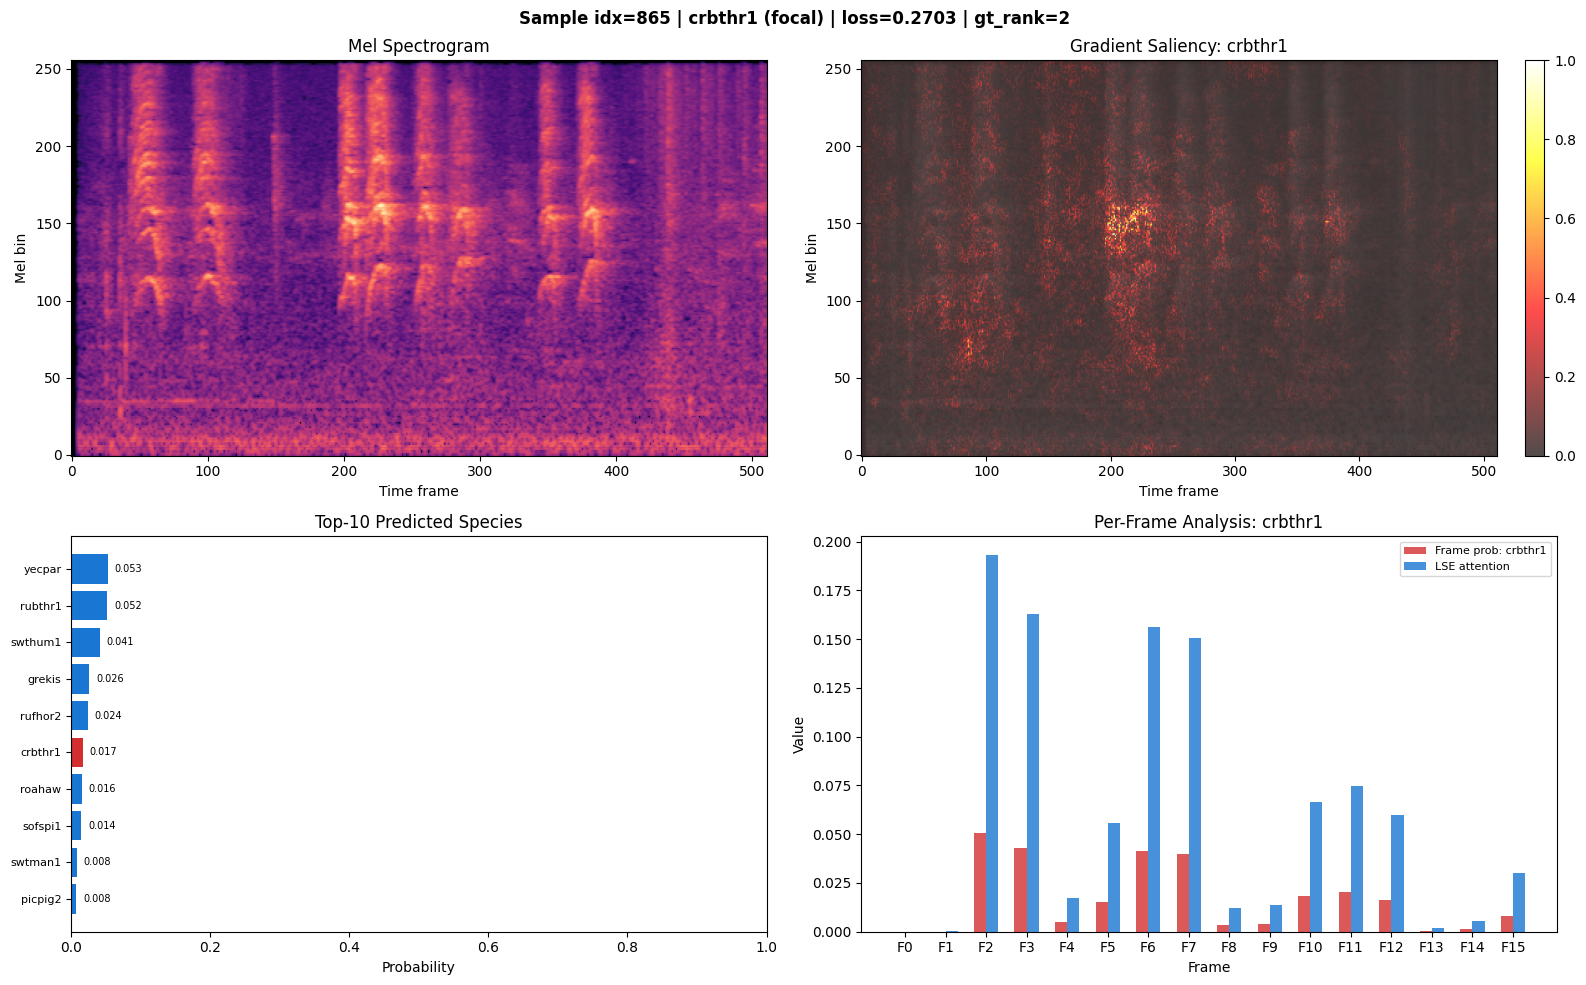

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# ---- Panel 1: Mel spectrogram ----
ax = axes[0, 0]
ax.imshow(result.mel, aspect="auto", origin="lower", cmap="magma")
ax.set_title("Mel Spectrogram")
ax.set_ylabel("Mel bin")
ax.set_xlabel("Time frame")

# ---- Panel 2: Gradient saliency overlay ----
ax = axes[0, 1]
ax.imshow(result.mel, aspect="auto", origin="lower", cmap="gray", alpha=0.4)
im = ax.imshow(
    result.gradient_saliency,
    aspect="auto",
    origin="lower",
    cmap="hot",
    alpha=0.7,
    vmin=0,
    vmax=1,
)
ax.set_title(f"Gradient Saliency: {result.species_name}")
ax.set_ylabel("Mel bin")
ax.set_xlabel("Time frame")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# ---- Panel 3: Top-10 species bar chart ----
ax = axes[1, 0]
top_k = 10
top_indices = np.argsort(result.clipwise_probs)[::-1][:top_k]
top_names = [species_list[i] for i in top_indices]
top_probs = [result.clipwise_probs[i] for i in top_indices]

colors = ["#d32f2f" if species_list[i] == result.species_name else "#1976d2" for i in top_indices]
bars = ax.barh(range(top_k), top_probs, color=colors)
ax.set_yticks(range(top_k))
ax.set_yticklabels(top_names, fontsize=8)
ax.set_xlabel("Probability")
ax.set_title("Top-10 Predicted Species")
ax.invert_yaxis()
ax.set_xlim(0, 1)

for bar, prob in zip(bars, top_probs, strict=False):
    ax.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{prob:.3f}",
        va="center",
        fontsize=7,
    )

# ---- Panel 4: Per-frame analysis ----
ax = axes[1, 1]
n_frames = result.frame_probs.shape[1]
frame_x = np.arange(n_frames)

target_frame_probs = result.frame_probs[result.species_idx]
ax.bar(
    frame_x - 0.15,
    target_frame_probs,
    width=0.3,
    color="#d32f2f",
    alpha=0.8,
    label=f"Frame prob: {result.species_name}",
)

ax.bar(
    frame_x + 0.15,
    result.effective_attention,
    width=0.3,
    color="#1976d2",
    alpha=0.8,
    label="LSE attention",
)

ax.set_xlabel("Frame")
ax.set_ylabel("Value")
ax.set_title(f"Per-Frame Analysis: {result.species_name}")
ax.legend(fontsize=8)
ax.set_xticks(frame_x)
ax.set_xticklabels([f"F{i}" for i in frame_x])

plt.suptitle(
    f"Sample idx={sample['idx']} | {sample['primary_label']} ({sample['source']}) | "
    f"loss={sample['loss']:.4f} | gt_rank={sample['gt_rank']}",
    fontsize=12,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## Compare: attribution for the top-1 predicted species

If the model predicted a wrong species, see what it's attending to for that species.

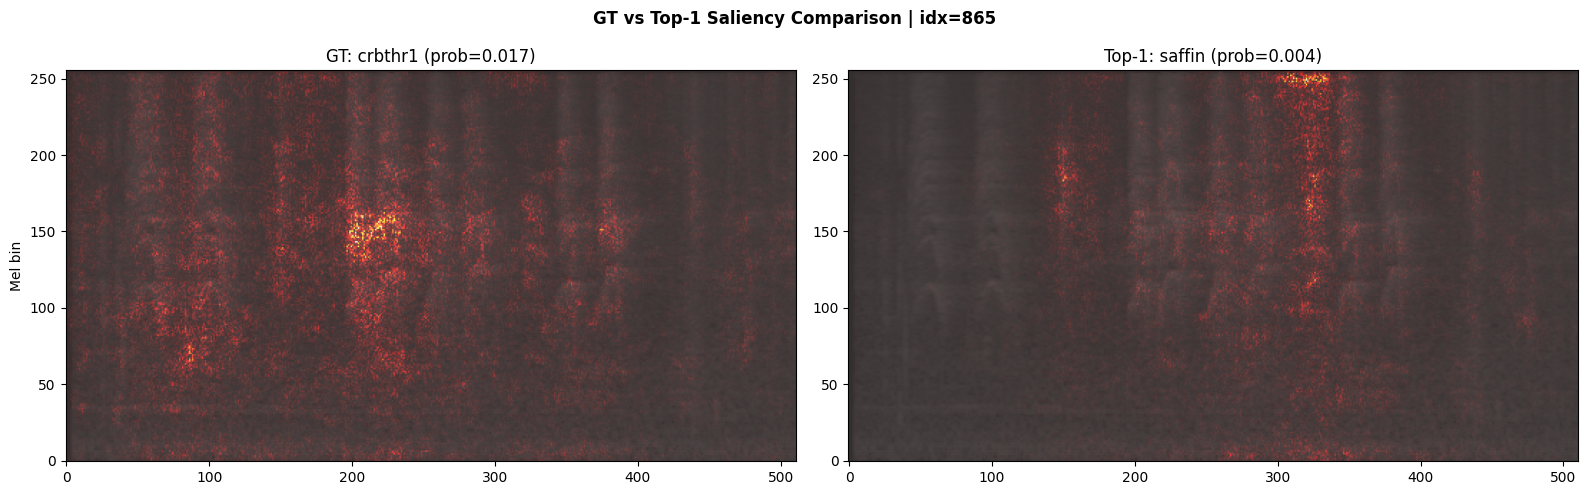

In [11]:
top1_species = sample["top1_species"]

if top1_species != target_species:
    top1_idx = species_list.index(top1_species)
    result_top1 = compute_attribution(
        model=model,
        mel_transform=mel_transform,
        waveform=waveform,
        species_idx=top1_idx,
        species_name=top1_species,
        lse_temperature=lse_temp,
        device="cpu",
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # GT species saliency
    ax = axes[0]
    ax.imshow(result.mel, aspect="auto", origin="lower", cmap="gray", alpha=0.4)
    ax.imshow(
        result.gradient_saliency,
        aspect="auto",
        origin="lower",
        cmap="hot",
        alpha=0.7,
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"GT: {target_species} (prob={result.clipwise_probs[target_idx]:.3f})")
    ax.set_ylabel("Mel bin")

    # Top-1 predicted species saliency
    ax = axes[1]
    ax.imshow(result_top1.mel, aspect="auto", origin="lower", cmap="gray", alpha=0.4)
    ax.imshow(
        result_top1.gradient_saliency,
        aspect="auto",
        origin="lower",
        cmap="hot",
        alpha=0.7,
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"Top-1: {top1_species} (prob={result_top1.clipwise_probs[top1_idx]:.3f})")

    plt.suptitle(f"GT vs Top-1 Saliency Comparison | idx={sample['idx']}", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print(f"Top-1 prediction matches GT ({target_species}) — no comparison needed.")

## Quick batch exploration

Run saliency on the top-5 highest-loss samples to look for patterns.

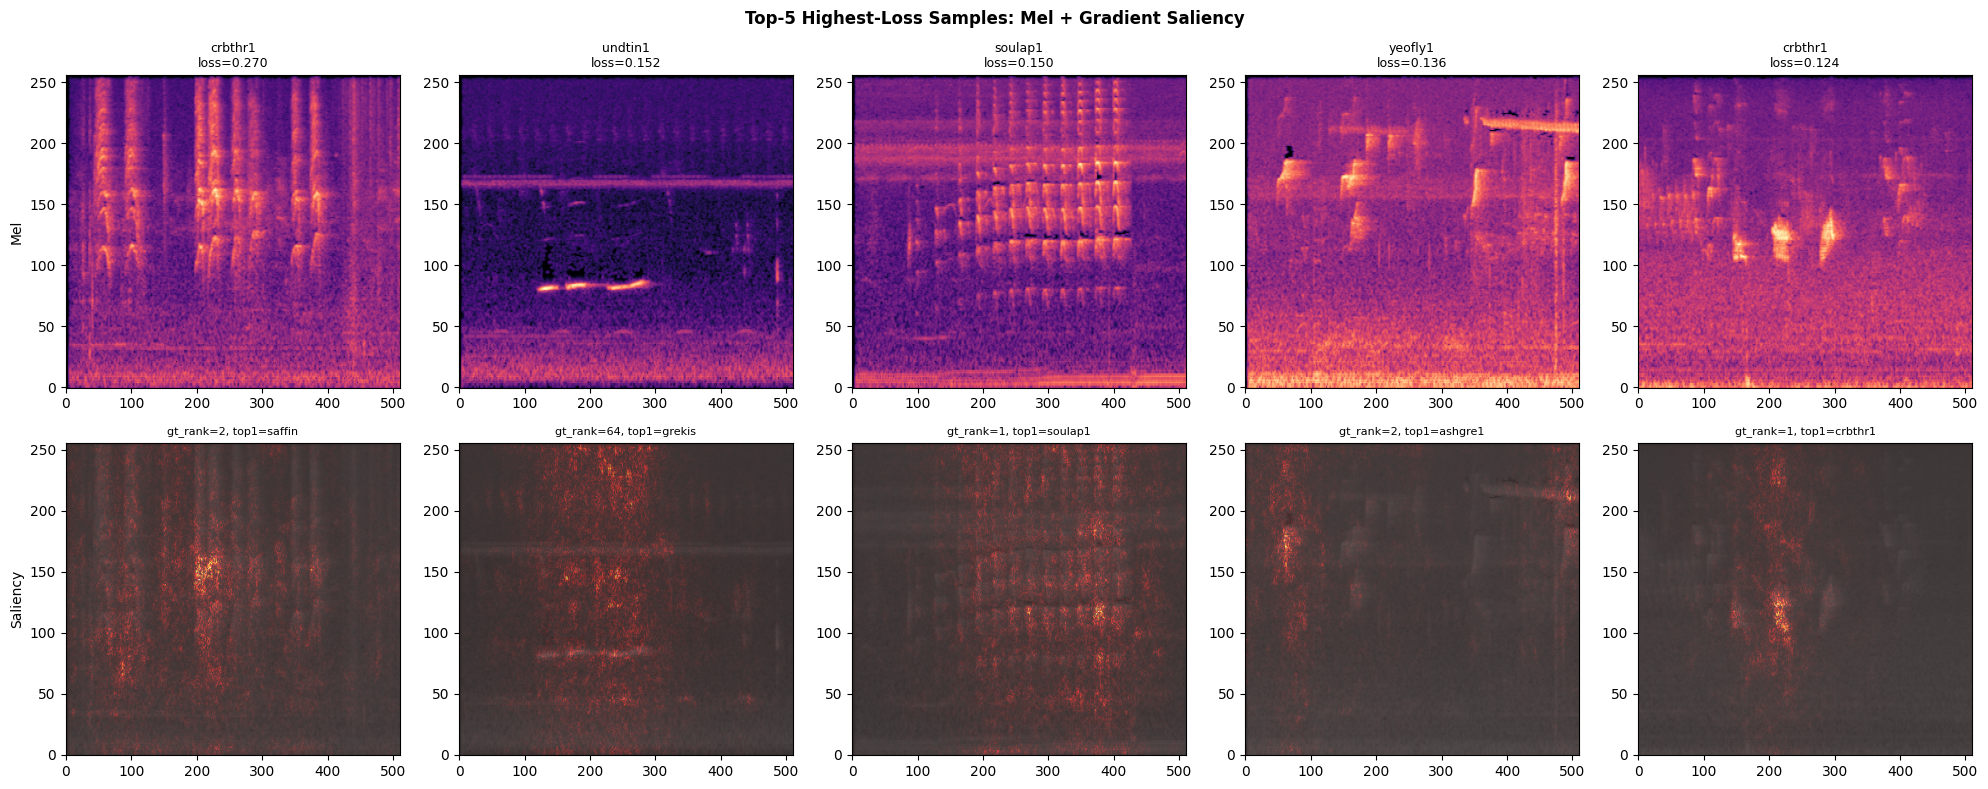

In [12]:
top5_losses = df.nlargest(5, "loss")

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

for col_idx, (_, row) in enumerate(top5_losses.iterrows()):
    wf = load_audio(row["filename"], sample_rate=SAMPLE_RATE, duration=WINDOW_DURATION)
    sp_idx = species_list.index(row["primary_label"])
    res = compute_attribution(
        model=model,
        mel_transform=mel_transform,
        waveform=wf,
        species_idx=sp_idx,
        species_name=row["primary_label"],
        lse_temperature=lse_temp,
        device="cpu",
    )

    # Mel spectrogram
    axes[0, col_idx].imshow(res.mel, aspect="auto", origin="lower", cmap="magma")
    axes[0, col_idx].set_title(f"{row['primary_label']}\nloss={row['loss']:.3f}", fontsize=9)
    if col_idx == 0:
        axes[0, col_idx].set_ylabel("Mel")

    # Saliency
    axes[1, col_idx].imshow(res.mel, aspect="auto", origin="lower", cmap="gray", alpha=0.4)
    axes[1, col_idx].imshow(
        res.gradient_saliency, aspect="auto", origin="lower", cmap="hot", alpha=0.7, vmin=0, vmax=1
    )
    axes[1, col_idx].set_title(f"gt_rank={row['gt_rank']}, top1={row['top1_species']}", fontsize=8)
    if col_idx == 0:
        axes[1, col_idx].set_ylabel("Saliency")

plt.suptitle("Top-5 Highest-Loss Samples: Mel + Gradient Saliency", fontweight="bold")
plt.tight_layout()
plt.show()